Epoch 1/5 | Generator Loss: 0.4945 | Discriminator Loss: 0.4892
Epoch 2/5 | Generator Loss: 0.9004 | Discriminator Loss: 0.2980
Epoch 3/5 | Generator Loss: 0.9189 | Discriminator Loss: 0.2661
Epoch 4/5 | Generator Loss: 1.0096 | Discriminator Loss: 0.2374
Epoch 5/5 | Generator Loss: 1.3602 | Discriminator Loss: 0.1620


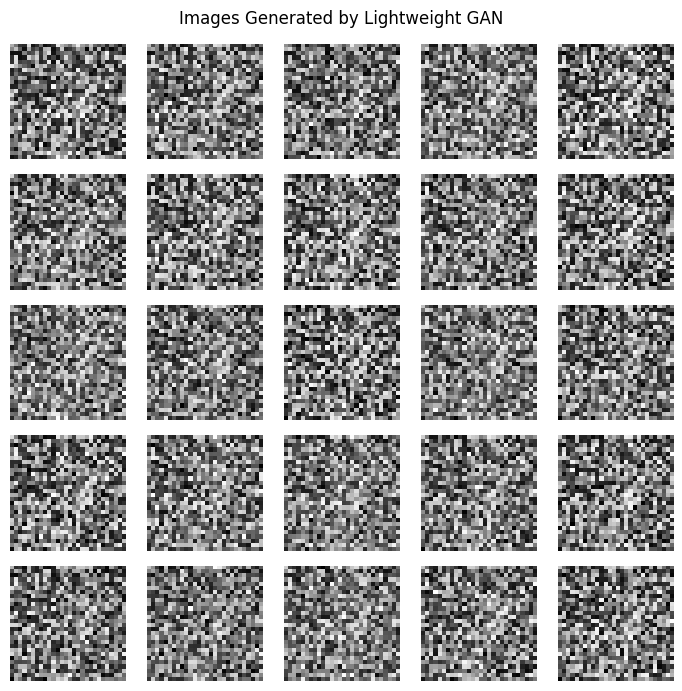

Training completed! Generator saved.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers

tf.random.set_seed(42)
np.random.seed(42)

# Load MNIST
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = x_train[..., np.newaxis]

# Use a smaller subset for faster training
x_train = x_train[:10000]

dataset = tf.data.Dataset.from_tensor_slices(x_train)
dataset = dataset.shuffle(10000).batch(256).prefetch(tf.data.AUTOTUNE)

# Generator
generator = tf.keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(128, activation="relu"),
    layers.Dense(784, activation="tanh"),
    layers.Reshape((28, 28, 1))
])

# Discriminator
discriminator = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1)
])

loss_fn = tf.keras.losses.BinaryCrossentropy(from_logits=True)

g_optimizer = tf.keras.optimizers.Adam(0.0002)
d_optimizer = tf.keras.optimizers.Adam(0.0002)

@tf.function
def train_step(real_images):
    batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([batch_size, 100])

    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake_images = generator(noise, training=True)

        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(fake_images, training=True)

        g_loss = loss_fn(tf.ones_like(fake_output), fake_output)
        d_loss = (
            loss_fn(tf.ones_like(real_output), real_output)
            + loss_fn(tf.zeros_like(fake_output), fake_output)
        ) / 2

    g_grad = gt.gradient(g_loss, generator.trainable_variables)
    d_grad = dt.gradient(d_loss, discriminator.trainable_variables)

    g_optimizer.apply_gradients(zip(g_grad, generator.trainable_variables))
    d_optimizer.apply_gradients(zip(d_grad, discriminator.trainable_variables))

    return g_loss, d_loss

# Train for 5 epochs
for epoch in range(5):
    for batch in dataset:
        g_loss, d_loss = train_step(batch)

    print(
        f"Epoch {epoch + 1}/5 | "
        f"Generator Loss: {g_loss.numpy():.4f} | "
        f"Discriminator Loss: {d_loss.numpy():.4f}"
    )

# Generate images
noise = tf.random.normal([25, 100])
images = generator(noise, training=False).numpy()

fig, axes = plt.subplots(5, 5, figsize=(7, 7))

for i, ax in enumerate(axes.flat):
    ax.imshow((images[i, :, :, 0] + 1) / 2, cmap="gray")
    ax.axis("off")

plt.suptitle("Images Generated by Lightweight GAN")
plt.tight_layout()
plt.show()

generator.save("/content/lightweight_gan.keras")
print("Training completed! Generator saved.")